# Project 4 - Classifiers
Commit history can be found at https://github.com/vigneshK0404/Data_Science_Projects.git

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_curve, roc_auc_score, log_loss
from sklearn.neural_network import MLPClassifier
import copy
from tqdm import tqdm

# Decision Tree Section

## 1 . Data Clean

In [2]:
df_raw = pd.read_csv("data/telescope_data.csv")
df = pd.DataFrame()
df = df_raw.drop(columns=df_raw.columns[0], inplace=False)
col_names = ["fLength","fWidth","fSize","fConc","fConc1","fAsym","fM3Long","fM3Trans","fAlpha","fDist","class"]
df.columns = col_names
df['class'] = label_binarize(df['class'], classes=['h', 'g']).ravel()

In [3]:
lowE = df[df["fSize"] < 3.0]
X = lowE.drop(columns=["class","fSize"],inplace=False)
class_labels = lowE["class"]

## 2 . Plotting Features

In [16]:
gamma_flag = (class_labels == 1)
gamma_lowE = lowE[gamma_flag]
cosmic_lowE = lowE[~gamma_flag]

def plot_pdf(gamma:pd.DataFrame, cosmic:pd.DataFrame ,nbins:int, xlabel:str, scale="linear") -> None:
    title = f"PDF of {xlabel}"
    _, bin_list, patches = plt.hist(gamma,bins=nbins,density=True, label="Gamma")
    plt.hist(cosmic,bins=bin_list,alpha=0.5 ,density=True, label="Cosmic")
    #plt.xlim(llim,hlim)
    plt.xlabel(xlabel+" [a.u]")
    plt.ylabel("Probability Density")
    plt.title(title)
    plt.yscale(scale)
    plt.legend()
    plt.show()


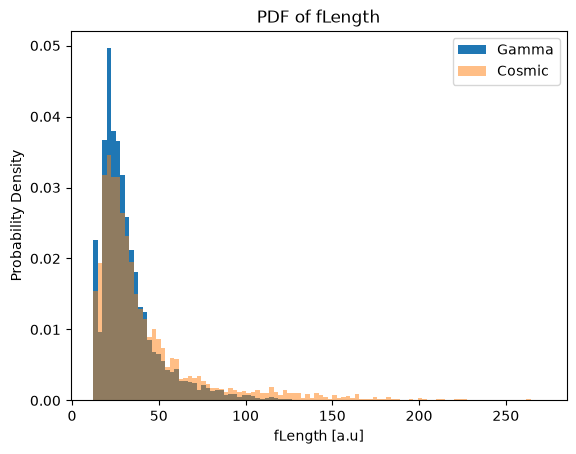

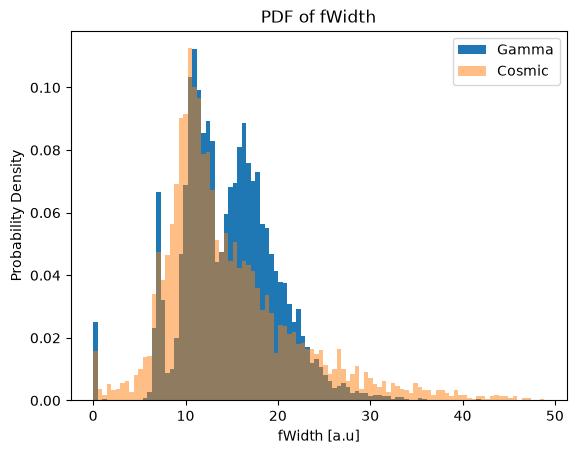

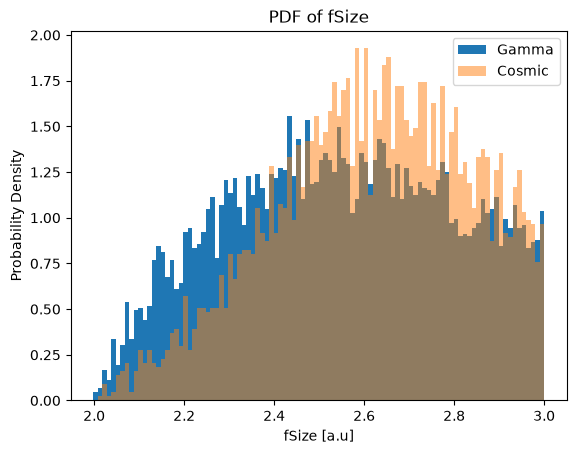

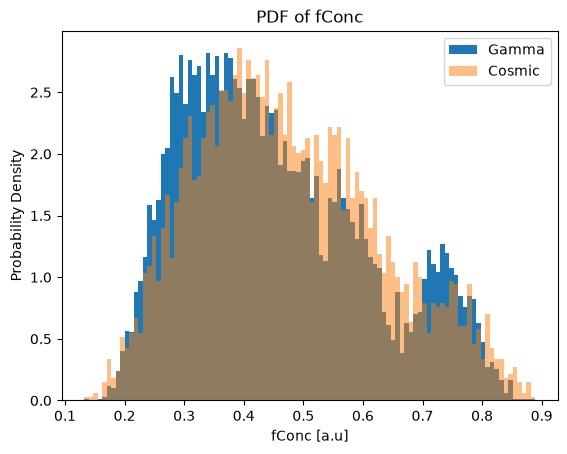

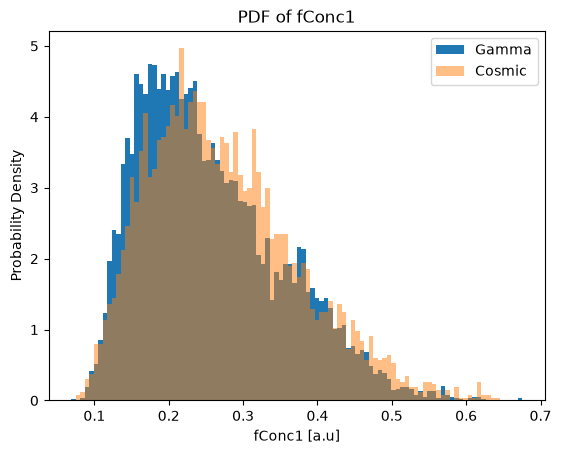

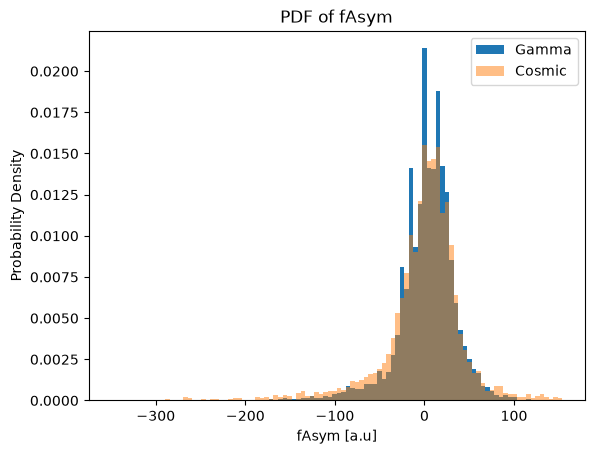

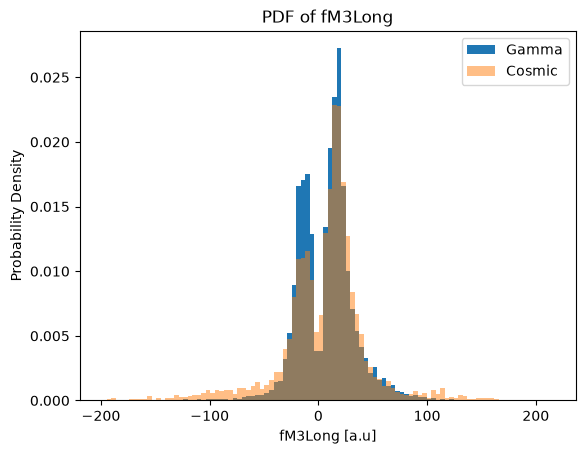

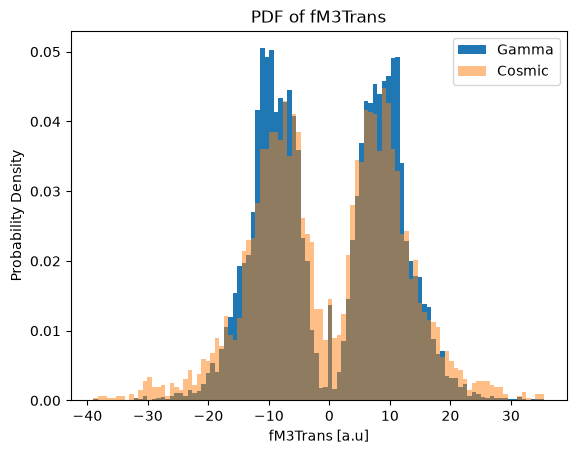

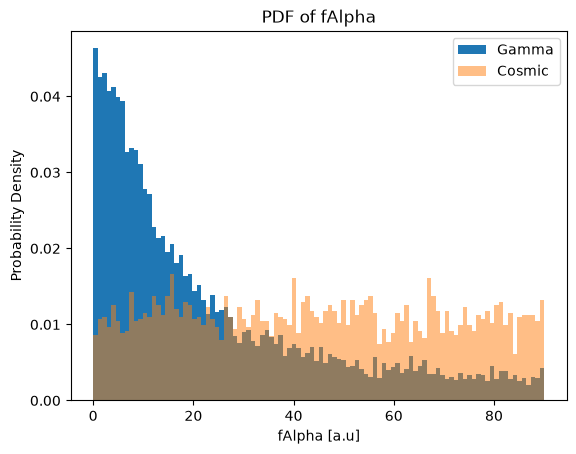

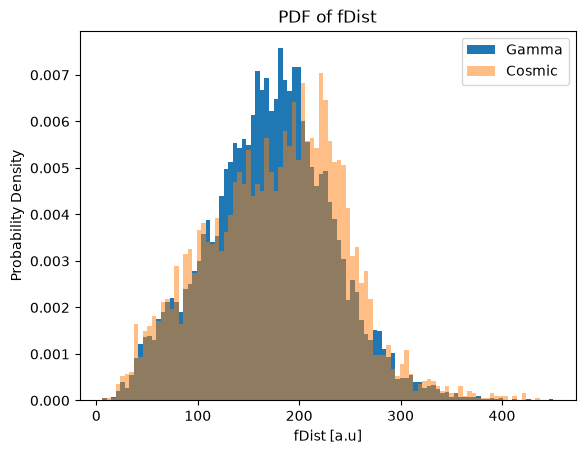

In [17]:
for col_name in lowE.columns[:-1]:
    plot_pdf(gamma_lowE[col_name], cosmic_lowE[col_name], 100, col_name)

## 3 . Train-Test Split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, class_labels, test_size=0.2, random_state=1, stratify=class_labels
)

I chose an 80/20 split to maximize the number of training samples while retaining sufficient statistics for the testing. Stratification was used to preserve the relative proportions signal and background in the datasets. The random state was fixed for reproducibility.

## 4 . Definition and Optimization on max_depth 

In [10]:
best_depth = 0
best_score_dtree = np.inf

auc_scores_test_dtree = []
auc_scores_train_dtree = []
max_depth_min = 1
max_depth_max = 50

md_list = list(range(max_depth_min,max_depth_max))
for md in md_list:
    D_tree = DecisionTreeClassifier(max_depth=md,min_samples_leaf=64,random_state=0)
    D_tree.fit(X_train,y_train)
    
    y_prob_test = D_tree.predict_proba(X_test)[:, 1]
    y_prob_train = D_tree.predict_proba(X_train)[:, 1]
    auc_test = roc_auc_score(y_test, y_prob_test)
    auc_train = roc_auc_score(y_train, y_prob_train)
    
    auc_scores_test_dtree.append(auc_test)
    auc_scores_train_dtree.append(auc_train)

    loss_dtree = log_loss(y_test, y_prob_test)
    
    if loss_dtree < best_score_dtree:
        best_score_dtree = loss_dtree
        best_depth = md
        
print(f"Best LogLoss score on test data with max_depth {best_depth}: {best_score_dtree :.3f} \n")

Best LogLoss score on test data with max_depth 9: 0.482 



In [13]:
for i in range(len(auc_scores_test_dtree)):
    print(f"max_depth {md_list[i]} : AUC {auc_scores_test_dtree[i] :.5f}")

max_depth 1 : AUC 0.65911
max_depth 2 : AUC 0.70240
max_depth 3 : AUC 0.73549
max_depth 4 : AUC 0.75613
max_depth 5 : AUC 0.78013
max_depth 6 : AUC 0.79703
max_depth 7 : AUC 0.80445
max_depth 8 : AUC 0.81136
max_depth 9 : AUC 0.81380
max_depth 10 : AUC 0.81110
max_depth 11 : AUC 0.80906
max_depth 12 : AUC 0.80939
max_depth 13 : AUC 0.80890
max_depth 14 : AUC 0.80879
max_depth 15 : AUC 0.80847
max_depth 16 : AUC 0.80879
max_depth 17 : AUC 0.80879
max_depth 18 : AUC 0.80879
max_depth 19 : AUC 0.80879
max_depth 20 : AUC 0.80879
max_depth 21 : AUC 0.80879
max_depth 22 : AUC 0.80879
max_depth 23 : AUC 0.80879
max_depth 24 : AUC 0.80879
max_depth 25 : AUC 0.80879
max_depth 26 : AUC 0.80879
max_depth 27 : AUC 0.80879
max_depth 28 : AUC 0.80879
max_depth 29 : AUC 0.80879
max_depth 30 : AUC 0.80879
max_depth 31 : AUC 0.80879
max_depth 32 : AUC 0.80879
max_depth 33 : AUC 0.80879
max_depth 34 : AUC 0.80879
max_depth 35 : AUC 0.80879
max_depth 36 : AUC 0.80879
max_depth 37 : AUC 0.80879
max_depth 

## 6 . Overfitting

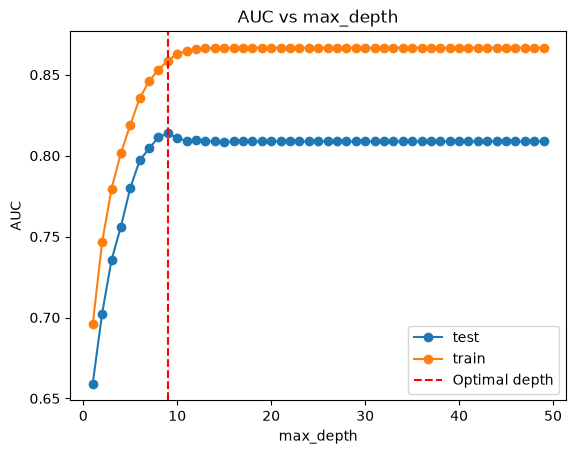

In [12]:
plt.plot(md_list, auc_scores_test_dtree, "-o", label="test")
plt.plot(md_list,auc_scores_train_dtree, "-o", label="train")
plt.xlabel("max_depth")
plt.ylabel("AUC")
plt.title("AUC vs max_depth")
plt.axvline(x=best_depth, color='red', linestyle='--', label='Optimal depth')
plt.legend()
plt.show()

After the Tree reaches optimal depth, Both test and training AUCs plateau. And uptil this point both grew in a similar fasion so the overfitting is as limited as it can be given the constraints of the problem. THere is however some evidence of overfitting, and that is the fact that training AUC plateaus at a larger value than test AUC.

## 7 . ROC Curve

In [9]:
def roc_curve_values(X,Y,best_clf):
    y_prob = best_clf.predict_proba(X)[:, 1]
    auc = roc_auc_score(Y, y_prob)
    fpr, tpr, _ = roc_curve(Y, y_prob)
    return fpr,tpr,auc

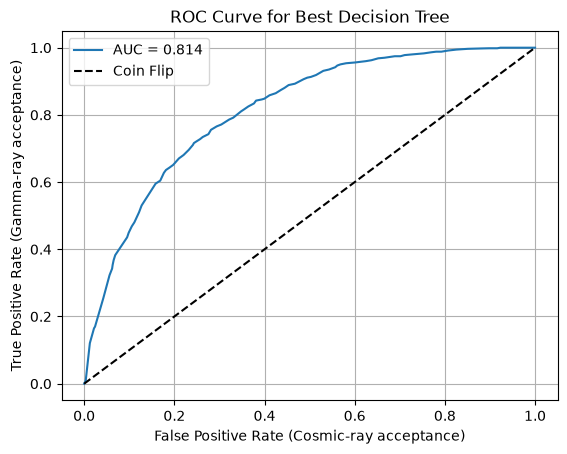

In [10]:
optimal_tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=64,random_state=0)
optimal_tree.fit(X_train,y_train)

optimal_tree_fpr, optimal_tree_tpr, auc_test_dtree_best = roc_curve_values(X_test,y_test,optimal_tree)


plt.plot(optimal_tree_fpr, optimal_tree_tpr, '-', label=f'AUC = {auc_test_dtree_best:.3f}')
plt.plot([0, 1], [0, 1], 'k--', label='Coin Flip')
plt.xlabel('False Positive Rate (Cosmic-ray acceptance)')
plt.ylabel('True Positive Rate (Gamma-ray acceptance)')
plt.title("ROC Curve for Best Decision Tree")
plt.legend()
plt.grid()
plt.show()

In [11]:
print(f"Best depth AUC : {auc_test_dtree_best :.3f}")

Best depth AUC : 0.814


## 8 . Most important features

In [12]:
sorted_idx = np.argsort(optimal_tree.feature_importances_)[::-1] 
print(f"The features in order of importance were : {list(X_train.columns[sorted_idx])}")
print(f"The least important feature was : {X_train.columns[sorted_idx[-1]]}")

The features in order of importance were : ['fAlpha', 'fLength', 'fWidth', 'fDist', 'fConc', 'fM3Long', 'fConc1', 'fM3Trans', 'fAsym']
The least important feature was : fAsym


I would keep fAlpha, fLength, fWidth, fDist, fConc. There features helped classify the signal the most. It also makes sense that fAlpha had significant differentiating power, it involves clear differences in the quantity for a cosmic vs gamma ray. I would drop fAsym, that too makes sense, it is related to the distance to the brightest pixel in the sky and that (to me) does not seem like a great indicator to differentiate between gamma and cosmic, it would depend on the energy of the incoming ray and the position (which does not help differentiate between gamma and cosmic).

# MLP Classifier

## 2 . Test Train Split

In [13]:
scaler = StandardScaler()
X_val, X_test_mlp, y_val, y_test_mlp = train_test_split(X_test,y_test,test_size=0.5,random_state=1,stratify=y_test)
scaler.fit(X_train)
X_train_std = scaler.transform(X_train)
X_test_mlp_std = scaler.transform(X_test_mlp)
X_val_std = scaler.transform(X_val)

I chose an 80/10/10 split to maximize the number of training samples while retaining sufficient statistics for the testing and validation. It was also a clean solution so I did not need to split up my training data again. I standardized the data so the absolute scale differences between features were not going to be a skewing factor.

## 3 . Training and Fitting

In [14]:
def iteration(hl_size, alpha=1e-3):
    clf = MLPClassifier(solver='sgd', 
                        batch_size=32,
                        activation="tanh",
                        learning_rate='constant', 
                        learning_rate_init=0.01,
                        shuffle=True, 
                        max_iter=200,
                        alpha=alpha,
                        hidden_layer_sizes=(hl_size,), 
                        random_state=1,         
                        early_stopping=False,
                       ) 

    epochs = 300
    patience = 20
    tol = 1e-3
    
    test_loss, val_loss, train_loss = [], [], []
    best_val, best_epoch, best_clf = np.inf, -1, None
    for epoch in range(epochs):
        clf.partial_fit(X_train_std, y_train, classes=[0, 1]) # one epoch of minibatch
        test_loss.append(log_loss(y_test_mlp, clf.predict_proba(X_test_mlp_std)[:, 1]))
        val_loss.append(log_loss(y_val, clf.predict_proba(X_val_std)[:, 1]))
        train_loss.append(log_loss(y_train, clf.predict_proba(X_train_std)[:, 1]))
    
        if val_loss[-1] < best_val - tol:   # a real improvement
            best_val, best_epoch = val_loss[-1], epoch
            best_clf = copy.deepcopy(clf) # Copy everything
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                break   

    return best_val, best_epoch, best_clf, test_loss, val_loss, train_loss
    
        

## 4 . Validation and Test vs Epoch

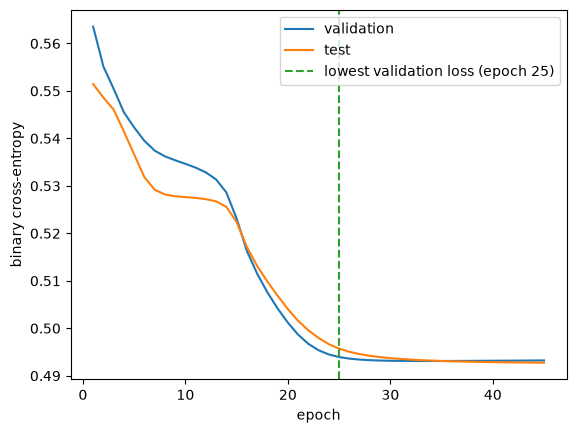

In [15]:
best_null_val, best_null_epoch, best_null_clf, test_null_loss, val_null_loss, _ = iteration(2)
plt.plot(np.arange(1, np.size(val_null_loss) + 1), val_null_loss, label="validation")
plt.plot(np.arange(1, np.size(test_null_loss) + 1), test_null_loss, label="test")

plt.axvline(best_null_epoch + 1, color="C2", ls="--", label=f"lowest validation loss (epoch {best_null_epoch + 1})")
plt.xlabel("epoch")
plt.ylabel("binary cross-entropy")
plt.legend()
plt.show()

In [16]:
best_null_test = log_loss(y_test_mlp, best_null_clf.predict_proba(X_test_mlp_std)[:, 1])
print(f"best epoch (from validation): {best_null_epoch + 1}")
print(f"validation loss at that epoch: {best_null_val:.4f}")
print(f"test loss at that epoch:       {best_null_test:.4f}")

best epoch (from validation): 25
validation loss at that epoch: 0.4939
test loss at that epoch:       0.4957


## 5 . Optimization

In [17]:
size_range = list(range(2,10))
optimal_size_mlp = None
optimal_hl_size = 0

optimal_size_mlp_val = np.inf
optimal_size_mlp_val_list = None
optimal_size_mlp_train_list = None
optimal_size_mlp_epoch = 0

for size in tqdm(size_range):
    best_val_i, best_epoch_i, best_clf_i, _, val_loss_i, train_loss_i = iteration(size)
    if best_val_i < optimal_size_mlp_val:
        optimal_size_mlp_val = best_val_i
        optimal_size_mlp = copy.deepcopy(best_clf_i)
        optimal_hl_size = size
        optimal_size_mlp_val_list = val_loss_i[:]
        optimal_size_mlp_train_list = train_loss_i[:]
        optimal_size_mlp_epoch = best_epoch_i

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:20<00:00,  2.62s/it]


Increasing the hidden_layer length should allow the model to capture more intricate details, however it also allows for overfitting. Since our criiteria is how well the validation loss does, we do not keep increasing the layer length infinitely.

## 6 . Validation and Training vs Epoch

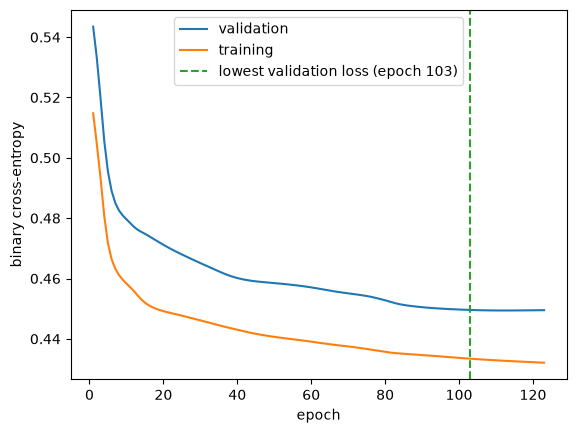

In [18]:
plt.plot(np.arange(1, np.size(optimal_size_mlp_val_list) + 1), optimal_size_mlp_val_list, label="validation")
plt.plot(np.arange(1, np.size(optimal_size_mlp_train_list) + 1), optimal_size_mlp_train_list, label="training")

plt.axvline(optimal_size_mlp_epoch + 1, color="C2", ls="--", label=f"lowest validation loss (epoch {optimal_size_mlp_epoch + 1})")
plt.xlabel("epoch")
plt.ylabel("binary cross-entropy")
plt.legend()
plt.show()

## 7 . Optimal vs Null Loss Comparison

In [19]:
optimal_size_mlp_test = log_loss(
    y_test_mlp,
    optimal_size_mlp.predict_proba(X_test_mlp_std)[:, 1]
)

print(f"Null MLP test loss: {best_null_test:.4f}")
print(f"Optimized MLP test loss: {optimal_size_mlp_test:.4f}")
print(f"Selected epoch: {optimal_size_mlp_epoch + 1}")

Null MLP test loss: 0.4957
Optimized MLP test loss: 0.4421
Selected epoch: 103


The optimized MLP has a lower test log loss than the small MLP. This indicates that the optimized model assigns higher probabilities to the correct classes. It has a lower nll which means it performs better at classification.

## 8 . ROC Curve

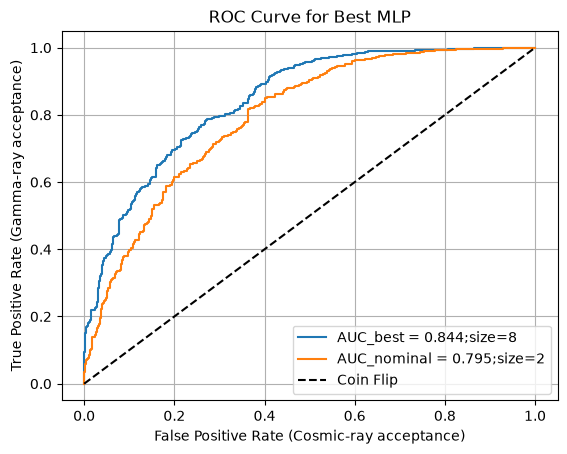

In [20]:
optimal_size_mlp_fpr, optimal_size_mlp_tpr, optimal_size_mlp_auc = roc_curve_values(X_test_mlp_std, y_test_mlp,optimal_size_mlp)
null_fpr, null_tpr, null_auc = roc_curve_values(X_test_mlp_std,y_test_mlp,best_null_clf)


plt.plot(optimal_size_mlp_fpr, optimal_size_mlp_tpr, '-', label=f'AUC_best = {optimal_size_mlp_auc:.3f};size={optimal_hl_size}')
plt.plot(null_fpr, null_tpr, '-', label=f'AUC_nominal = {null_auc:.3f};size=2')
plt.plot([0, 1], [0, 1], 'k--', label='Coin Flip')
plt.xlabel('False Positive Rate (Cosmic-ray acceptance)')
plt.ylabel('True Positive Rate (Gamma-ray acceptance)')
plt.title("ROC Curve for Best MLP")
plt.legend()
plt.grid()
plt.show()

## 9 . L2 Regularization 

In [21]:
optimal_mlp_val = np.inf
optimal_mlp = None
optimal_alpha = 0
for a in tqdm([1e-1,1e-3,1e-5]):
    best_val_i, _, best_clf_i, _, _ , _ = iteration(optimal_hl_size,a)
    if best_val_i < optimal_mlp_val:
        optimal_mlp_val = best_val_i
        optimal_mlp = copy.deepcopy(best_clf_i)
        optimal_alpha = a

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:09<00:00,  3.04s/it]


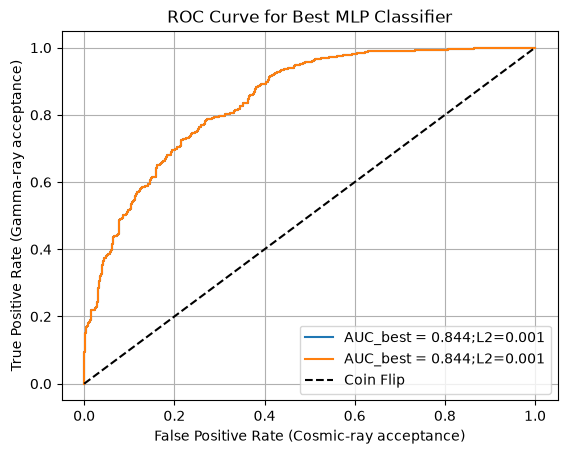

In [22]:
optimal_mlp_fpr, optimal_mlp_tpr, optimal_mlp_auc = roc_curve_values(X_test_mlp_std,y_test_mlp,optimal_mlp)

plt.plot(optimal_mlp_fpr, optimal_mlp_tpr, '-', label=f'AUC_best = {optimal_mlp_auc:.3f};L2={optimal_alpha}')
plt.plot(optimal_size_mlp_fpr, optimal_size_mlp_tpr, '-', label=f'AUC_best = {optimal_size_mlp_auc:.3f};L2=0.001')
plt.plot([0, 1], [0, 1], 'k--', label='Coin Flip')
plt.xlabel('False Positive Rate (Cosmic-ray acceptance)')
plt.ylabel('True Positive Rate (Gamma-ray acceptance)')
plt.title("ROC Curve for Best MLP Classifier")
plt.legend()
plt.grid()
plt.show()

Of the three L2 regularization parameters considered, I would prefer L2=0.001 since it resulted in the lowest selected validation loss.